# Experimento 02 - Análise Temática de Diálogos

##### Teste em ambientes muito controlados

In [ ]:
#pip install -r requirements.txt

In [2]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

from langchain_openai import AzureOpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

from PyPDF2 import PdfReader, PdfWriter

from dotenv import load_dotenv
import os

### Seis pessoas falando palavras de assuntos diferentes

In [3]:
file_path_palavras = "pdfs/palavras_desconexas.pdf"
loader_palavras = PyPDFLoader(file_path_palavras)
pages_palavras = loader_palavras.load()

print(f"{len(pages_palavras)} páginas")

splitter = RecursiveCharacterTextSplitter(
    chunk_size=2000,
    chunk_overlap=500,
    separators=["\n\n"],  
)

texto_palavras = "\n\n".join([p.page_content for p in pages_palavras])

chunks_palavras = re.split(r'(?=\b[A-ZÁÉÍÓÚÂÊÔÃÕ][a-záéíóúãõç]+\s-\s)', texto_palavras)
chunks_palavras = [c.strip() for c in chunks_palavras if c.strip() != ""]

print(f"Total de chunks: {len(chunks_palavras)}")


load_dotenv()

embeddings = AzureOpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

vetor_palavras = np.array(embeddings.embed_documents(chunks_palavras))

tsne_palavras = TSNE(n_components=2, random_state=42, perplexity=2)
vectors_tsne_palavras = tsne_palavras.fit_transform(vetor_palavras)

num_clusters_palavras = 3
kmeans_palavras = KMeans(n_clusters=num_clusters_palavras, random_state=42)
clusters_palavras = kmeans_palavras.fit_predict(vectors_tsne_palavras)

1 páginas
Total de chunks: 6


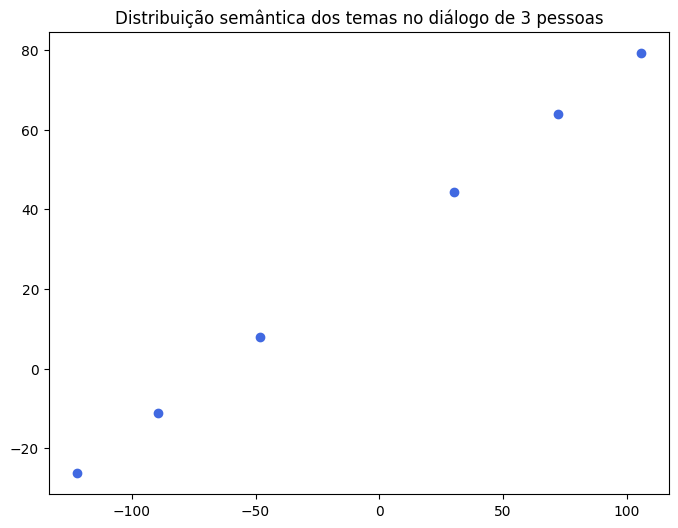

In [4]:
plt.figure(figsize=(8,6))
plt.scatter(vectors_tsne_palavras[:,0], vectors_tsne_palavras[:,1], color="royalblue")
plt.title("Distribuição semântica dos temas no diálogo de 3 pessoas")
plt.show()